# Shoplifting Detection with a 3D CNN

**Goal:** look at a short video clip and decide: *normal shopping* (0) or *shoplifting* (1).

**The idea in simple words:** a single picture can't tell you someone is stealing, because stealing is an *action over time*. So we give the model a small stack of frames (a "mini movie") and use a **3D CNN**, which slides its filters across width, height **and time**, so it can notice movement patterns.

**Before you run (Kaggle):** turn on **GPU** (Settings → Accelerator) and **Internet** (Settings → Internet), because the notebook pulls the data straight from Google Drive.

## 1. Setup and settings
All the knobs live in this one cell.

In [10]:
import os, sys, subprocess, zipfile, random, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ---------------- settings ----------------
SEED = 42
FILE_ID = "1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-"       # Google Drive file id of "Shop DataSet.zip"

T = 16               # frames per clip (the "target frame count")
RESIZE = 128         # every frame is resized to RESIZE x RESIZE and cached
CROP = 112           # the model sees CROP x CROP (random crop in training, center crop otherwise)
BATCH_SIZE = 8
EPOCHS = 25
LR = 3e-4
PATIENCE = 7         # stop if validation F1 does not improve for this many epochs
MODEL_NAME = "simple3dcnn"   # "simple3dcnn" (built from scratch)  or  "r3d18" (pretrained 3D ResNet)
NUM_WORKERS = 2

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
ZIP_PATH = f"{WORK}/shop_dataset.zip"
DATA_DIR = os.environ.get("SHOP_DATA_DIR", f"{WORK}/shop_data")
CACHE_DIR = f"{WORK}/frame_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU (training will be slow)")

device: cuda | Tesla T4


## 2. Get the data from Google Drive (no manual download)
Kaggle can't "mount" Drive like Colab, so the notebook uses `gdown` to copy the zip from Drive **directly onto Kaggle's disk**, unzips it, and deletes the zip. Nothing passes through your own computer.

The Drive file must be shared as **"Anyone with the link"**, and **Internet must be ON** in the notebook settings. This cell skips the download if the data is already there, and it also automatically uses the data if you attach it to the notebook with **Add Input** (a Kaggle Dataset holding the videos or the zip).

In [11]:
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".wmv", ".flv", ".mpg", ".mpeg", ".webm", ".m4v"}

def list_videos(folder):
    out = []
    for p in Path(folder).rglob("*"):
        if p.is_file() and p.suffix.lower() in VIDEO_EXTS and "__MACOSX" not in p.parts and not p.name.startswith("._"):
            out.append(p)
    return sorted(out)

def find_attached_data():
    """Is the data already attached to this notebook via 'Add Input'? (videos or a zip)"""
    inp = Path("/kaggle/input")
    if not inp.exists():
        return None, None
    if list_videos(inp):
        return "videos", inp
    zips = sorted(inp.rglob("*.zip"))
    return ("zip", zips[0]) if zips else (None, None)

def unzip_to(zip_path, target):
    print("Unzipping", zip_path, "...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(target)

kind, src = find_attached_data()
if kind == "videos":
    DATA_DIR = str(src)                                    # read the attached videos directly
    print("Using data attached to this notebook:", DATA_DIR)
elif len(list_videos(DATA_DIR)) > 0:
    print("Data already available in", DATA_DIR)
elif kind == "zip":
    unzip_to(src, DATA_DIR)
else:
    print("Downloading from Google Drive (about 1.7 GB, this takes a few minutes)...")
    try:
        out = gdown.download(url=f"https://drive.google.com/uc?id={FILE_ID}", output=ZIP_PATH, quiet=False)
    except Exception as e:
        raise RuntimeError(
            "Could not reach Google Drive. On Kaggle this almost always means Internet is OFF for the notebook: "
            "open the notebook's Settings panel (right side) and switch Internet ON "
            "(Kaggle asks you to verify your phone number the first time)."
        ) from e
    if out is None or not os.path.exists(ZIP_PATH):
        raise RuntimeError(
            "gdown reached Drive but could not fetch the file. Check that the Drive file is shared with "
            "'Anyone with the link', and that Drive's daily download quota is not exceeded "
            "(if it is, wait a few hours or make a copy of the file in your own Drive and use that file id)."
        )
    unzip_to(ZIP_PATH, DATA_DIR)
    os.remove(ZIP_PATH)

print("video files found:", len(list_videos(DATA_DIR)))

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=ef0a94a5-d811-40da-91e9-3f0333b49434
To: /kaggle/working/shop_dataset.zip
100%|██████████| 1.78G/1.78G [00:11<00:00, 158MB/s] 


Unzipping /kaggle/working/shop_dataset.zip ...
video files found: 855


## 3. Find the videos and their labels
The label comes from the **folder name**: a folder whose name says "normal" or "non..." → 0, a folder whose name says "shoplift/theft/steal" → 1. Check the printed table to make sure the classes were read correctly.

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np


def label_from_path(p, root):
    """
    Assign labels based on the video directory structure.

    0 = normal / non-shoplifting
    1 = shoplifting
    """

    # Get the parent folder names and normalize their formatting
    parts = [
        " ".join(
            part.lower()
            .replace("_", " ")
            .replace("-", " ")
            .split()
        )
        for part in p.relative_to(root).parts[:-1]
    ]

    # Check negative-class folders FIRST
    # This prevents "non shop lifters" from being labeled as shoplifting.
    if any(
        "normal" in part or "non" in part.split()
        for part in parts
    ):
        return 0

    # Check positive-class folders
    if any(
        keyword in part
        for part in parts
        for keyword in [
            "shop lifter",
            "shoplift",
            "theft",
            "steal",
            "thief",
        ]
    ):
        return 1

    # No recognizable class folder
    return None


# Set the dataset root directory
root = Path(DATA_DIR)

# Collect video paths and assign labels
rows = []

for p in list_videos(root):
    rows.append({
        "path": str(p),
        "folder": str(p.parent.relative_to(root)),
        "label": label_from_path(p, root),
    })

df = pd.DataFrame(rows)

# Check for videos whose class could not be identified
unknown = df[df["label"].isna()]

if len(unknown) > 0:
    print(
        f"WARNING: {len(unknown)} videos had no recognizable class folder "
        "and will be dropped."
    )
    print("Example folders:", unknown["folder"].unique()[:10])

# Keep only videos with recognized labels
df = df.dropna(subset=["label"]).reset_index(drop=True)

# Convert labels to integers
df["label"] = df["label"].astype(int)

# Add human-readable class names
df["class_name"] = df["label"].map({
    0: "normal",
    1: "shoplifting",
})

# Assign a unique ID to each video
df["vid"] = np.arange(len(df))

# Display the number of videos in each folder and class
print("\nVideos per folder and class:")
print(df.groupby(["folder", "class_name"]).size().rename("clips"))

# Display the overall class distribution
print("\nOverall class distribution:")
print(df["class_name"].value_counts())

print("\nTotal labeled videos:", len(df))
print("Unique labels:", sorted(df["label"].unique()))

# Validate the dataset
assert not df.empty, "No labeled videos were found. Check DATA_DIR."

assert df["label"].nunique() == 2, (
    "Expected two classes, but found only one. "
    "Check the dataset folder names and label_from_path()."
)

assert df["path"].is_unique, "Duplicate video paths detected."

assert df["label"].notna().all(), "Some videos have missing labels."

print("\n✅ Both classes were recognized successfully!")


Videos per folder and class:
folder                         class_name 
Shop DataSet/non shop lifters  normal         531
Shop DataSet/shop lifters      shoplifting    324
Name: clips, dtype: int64

Overall class distribution:
class_name
normal         531
shoplifting    324
Name: count, dtype: int64

Total labeled videos: 855
Unique labels: [np.int64(0), np.int64(1)]

✅ Both classes were recognized successfully!


## 4. Explore the dataset (Task 1)
Clips per class, clip duration, and frame resolution.

reading video metadata:   0%|          | 0/855 [00:00<?, ?it/s]

Total clips: 855

Clips per class:
 class_name
normal         531
shoplifting    324

Duration (seconds) per class:
              count   mean   std  min   25%   50%   75%    max
class_name                                                   
normal       531.0  13.93  5.37  3.0  11.0  14.0  16.0  74.00
shoplifting  324.0  12.22  3.35  4.0  10.0  12.0  15.0  23.03

Frame count per class:
              count   mean    std    min    25%    50%    75%     max
class_name                                                          
normal       531.0  347.8  134.2   75.0  275.0  348.0  400.0  1850.0
shoplifting  324.0  304.6   83.5  100.0  248.0  300.0  372.0   570.0

Frame resolutions:
 resolution
704x576    855

FPS values:
 fps
25.0    666
24.8    189


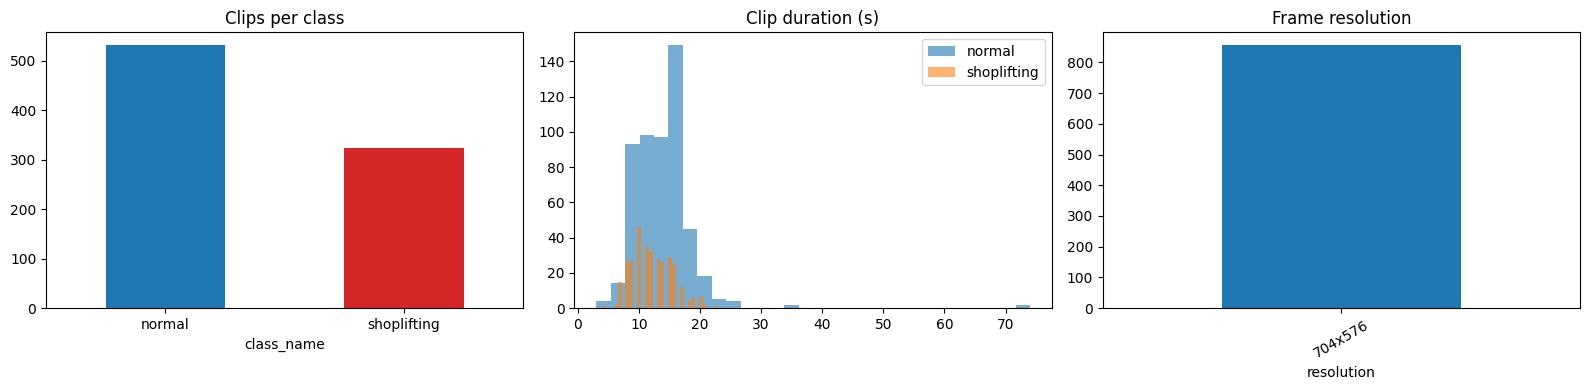

In [14]:
def video_info(path):
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return n, fps, w, h

with ThreadPoolExecutor(8) as ex:
    infos = list(tqdm(ex.map(video_info, df.path), total=len(df), desc="reading video metadata"))
df[["n_frames", "fps", "width", "height"]] = pd.DataFrame(infos, columns=["n_frames", "fps", "width", "height"], index=df.index)

broken = df[df.n_frames <= 0]
if len(broken):
    print(f"Dropping {len(broken)} unreadable videos")
df = df[df.n_frames > 0].reset_index(drop=True)
df["vid"] = np.arange(len(df))
df["duration_s"] = df.n_frames / df.fps.replace(0, np.nan)
df["resolution"] = df.width.astype(str) + "x" + df.height.astype(str)

print("Total clips:", len(df))
print("\nClips per class:\n", df.class_name.value_counts().to_string())
print("\nDuration (seconds) per class:\n", df.groupby("class_name").duration_s.describe().round(2).to_string())
print("\nFrame count per class:\n", df.groupby("class_name").n_frames.describe().round(1).to_string())
print("\nFrame resolutions:\n", df.resolution.value_counts().head(10).to_string())
print("\nFPS values:\n", df.fps.round(1).value_counts().head(5).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.class_name.value_counts().plot.bar(ax=ax[0], color=["tab:blue", "tab:red"]); ax[0].set_title("Clips per class"); ax[0].tick_params(axis="x", rotation=0)
for name, g in df.groupby("class_name"):
    ax[1].hist(g.duration_s.dropna(), bins=30, alpha=0.6, label=name)
ax[1].set_title("Clip duration (s)"); ax[1].legend()
df.resolution.value_counts().head(8).plot.bar(ax=ax[2]); ax[2].set_title("Frame resolution"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 5. Frame sampling strategy (Task 2)
Every video has a different length, but the model needs exactly `T` frames.

**Rule:** the **skip interval** is `skip = total_frames / T`. We cut the video into `T` equal chunks, each `skip` frames long, and take the frame in the **middle of each chunk**. So the sampled frames cover the whole video, from beginning to end, with equal spacing.

Example: 160 frames and T = 16 → skip = 10 → frames 5, 15, 25, ..., 155.
If a video has fewer than `T` frames, some frames are simply repeated.

n_frames= 160  skip= 10.00  -> [5, 15, 25, 35, 45, 55, 65, 75, 85, 95, 105, 115, 125, 135, 145, 155]
n_frames= 100  skip=  6.25  -> [3, 9, 15, 21, 28, 34, 40, 46, 53, 59, 65, 71, 78, 84, 90, 96]
n_frames=  37  skip=  2.31  -> [1, 3, 5, 8, 10, 12, 15, 17, 19, 21, 24, 26, 28, 31, 33, 35]
n_frames=  10  skip=  0.62  -> [0, 0, 1, 2, 2, 3, 4, 4, 5, 5, 6, 7, 7, 8, 9, 9]


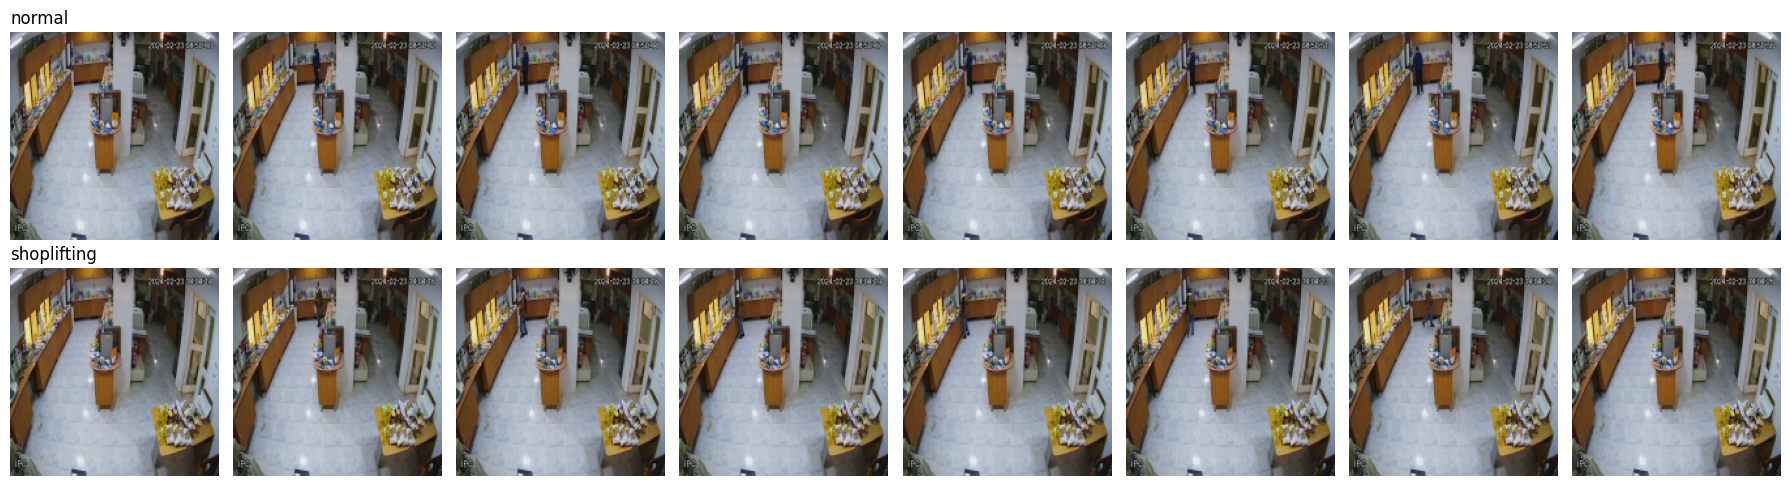

In [15]:
def uniform_indices(n_frames, T):
    """Return T frame numbers, evenly spread over a video with n_frames frames."""
    if n_frames <= 0:
        return np.zeros(T, dtype=int)
    skip = n_frames / T                                   # uniform skip interval (can be fractional)
    idx = np.floor(np.arange(T) * skip + skip / 2).astype(int)   # middle of every chunk
    return np.clip(idx, 0, n_frames - 1)

for n in [160, 100, 37, 10]:
    print(f"n_frames={n:4d}  skip={n/T:6.2f}  ->", uniform_indices(n, T).tolist())


def read_sampled_frames(path, T, size):
    """Decode only the wanted frames. Returns uint8 array (T, size, size, 3) in RGB."""
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idx = uniform_indices(n, T)
    wanted, last = set(idx.tolist()), int(idx.max())
    got, i = {}, 0
    while i <= last:
        if not cap.grab():
            break
        if i in wanted:
            ok, f = cap.retrieve()
            if ok:
                got[i] = cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), (size, size), interpolation=cv2.INTER_AREA)
        i += 1
    cap.release()
    if not got:
        return np.zeros((T, size, size, 3), dtype=np.uint8)
    keys = np.array(sorted(got))
    # if a frame could not be decoded, reuse the closest one that could
    return np.stack([got[int(keys[np.abs(keys - j).argmin()])] for j in idx])


# look at one clip from each class
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for r, cname in enumerate(["normal", "shoplifting"]):
    sample = df[df.class_name == cname].iloc[0]
    fr = read_sampled_frames(sample.path, 8, 160)
    for c in range(8):
        axes[r, c].imshow(fr[c]); axes[r, c].axis("off")
    axes[r, 0].set_title(cname, loc="left")
plt.tight_layout(); plt.show()

## 6. Decode once, cache the frames
Decoding video is slow. We sample the `T` frames of every video **one time**, store them as small `.npy` files, and training then just loads those. (The random augmentation is still applied fresh every epoch.)

In [16]:
def cache_file(vid):
    return os.path.join(CACHE_DIR, f"{vid}_T{T}_S{RESIZE}.npy")

def build_one(args):
    vid, path = args
    f = cache_file(vid)
    if not os.path.exists(f):
        np.save(f, read_sampled_frames(path, T, RESIZE))

jobs = list(zip(df.vid, df.path))
with ThreadPoolExecutor(4) as ex:
    list(tqdm(ex.map(build_one, jobs), total=len(jobs), desc="sampling frames"))
print("cached clips:", len(os.listdir(CACHE_DIR)))

sampling frames:   0%|          | 0/855 [00:00<?, ?it/s]

cached clips: 855


## 7. Consistent augmentation (Task 3)
Augmentation makes training clips slightly different every epoch so the model doesn't memorise them. For video, the **same random choices must be used for every frame of a clip**, otherwise the object would "jump" between frames and motion would be destroyed.

How we guarantee it: the random numbers (flip yes/no, crop position, brightness, contrast, saturation) are drawn **once per clip**, and then applied to the whole `(T, C, H, W)` tensor in one go.

In [17]:
MEAN = torch.tensor([0.43216, 0.394666, 0.37645]).view(1, 3, 1, 1)   # standard video-model statistics
STD = torch.tensor([0.22803, 0.22145, 0.216989]).view(1, 3, 1, 1)

def clip_augment(x):
    """x: (T, C, H, W) float in [0, 1]. One set of random parameters for the WHOLE clip."""
    Tn, C, H, W = x.shape
    # 1) horizontal flip (same decision for all frames)
    if random.random() < 0.5:
        x = x.flip(-1)
    # 2) random crop (same box for all frames)
    top = random.randint(0, H - CROP)
    left = random.randint(0, W - CROP)
    x = x[:, :, top:top + CROP, left:left + CROP]
    # 3) colour jitter (same factors for all frames)
    b = random.uniform(0.8, 1.2)      # brightness
    c = random.uniform(0.8, 1.2)      # contrast
    s = random.uniform(0.8, 1.2)      # saturation
    x = x * b
    m = x.mean()
    x = (x - m) * c + m
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = gray + (x - gray) * s
    return x.clamp(0, 1)

def center_crop(x):
    H, W = x.shape[-2:]
    top, left = (H - CROP) // 2, (W - CROP) // 2
    return x[:, :, top:top + CROP, left:left + CROP]

# sanity check: a "clip" made of ONE frame repeated T times must stay identical across time after augmentation
frame = torch.rand(1, 3, RESIZE, RESIZE)
test_clip = frame.repeat(T, 1, 1, 1)
for _ in range(5):
    out = clip_augment(test_clip)
    assert torch.allclose(out[0], out[-1], atol=1e-6), "augmentation is NOT consistent across frames!"
print("OK: the same flip / crop / colour jitter is applied to every frame of a clip. Output shape:", tuple(out.shape))

OK: the same flip / crop / colour jitter is applied to every frame of a clip. Output shape: (16, 3, 112, 112)


## 8. PyTorch Dataset (Task 4)
Each item is a tensor of shape **(T, C, H, W)** plus its label. We also split the clips into train / validation / test (70 / 15 / 15), keeping the class ratio the same in every part.

In [18]:
class ShopVideoDataset(Dataset):
    def __init__(self, frame, train):
        self.vids = frame.vid.tolist()
        self.labels = frame.label.tolist()
        self.train = train

    def __len__(self):
        return len(self.vids)

    def __getitem__(self, i):
        frames = np.load(cache_file(self.vids[i]))                       # (T, H, W, 3) uint8
        x = torch.from_numpy(frames).permute(0, 3, 1, 2).float() / 255.  # (T, C, H, W) in [0, 1]
        x = clip_augment(x) if self.train else center_crop(x)
        x = (x - MEAN) / STD
        return x, torch.tensor(self.labels[i], dtype=torch.long)


train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label, random_state=SEED)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")
print(pd.DataFrame({"train": train_df.class_name.value_counts(),
                    "val": val_df.class_name.value_counts(),
                    "test": test_df.class_name.value_counts()}).to_string())

train_ds = ShopVideoDataset(train_df, train=True)
val_ds = ShopVideoDataset(val_df, train=False)
test_ds = ShopVideoDataset(test_df, train=False)

pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin, drop_last=len(train_ds) > BATCH_SIZE)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

x, y = train_ds[0]
print("one sample:", tuple(x.shape), "(T, C, H, W) | label:", int(y))
xb, yb = next(iter(train_loader))
print("one batch :", tuple(xb.shape), "(B, T, C, H, W)")

train 598 | val 128 | test 129
             train  val  test
class_name                   
normal         371   80    80
shoplifting    227   48    49
one sample: (16, 3, 112, 112) (T, C, H, W) | label: 0
one batch : (8, 16, 3, 112, 112) (B, T, C, H, W)


## 9. The 3D CNN (Task 5, option a)
A normal 2D CNN filter is a small square (3×3) that slides over an image. A **3D filter is a small cube (3×3×3)** that slides over the image *and* through time, so it reacts to patterns like "a hand moves toward a pocket".

Our network: 4 blocks of `Conv3d → BatchNorm → ReLU → MaxPool3d`, then average everything down to one vector and classify into 2 classes. The model takes the full clip `(B, T, C, H, W)` and internally reorders it to `(B, C, T, H, W)`, which is what `Conv3d` expects.

Set `MODEL_NAME = "r3d18"` at the top to use a 3D ResNet pretrained on Kinetics-400 instead. With small datasets, pretrained weights usually help a lot.

In [19]:
class Simple3DCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        def block(cin, cout, pool):
            return nn.Sequential(
                nn.Conv3d(cin, cout, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm3d(cout),
                nn.ReLU(inplace=True),
                nn.MaxPool3d(pool),
            )
        self.features = nn.Sequential(
            block(3, 32, (1, 2, 2)),      # keep time resolution early, shrink space
            block(32, 64, (2, 2, 2)),
            block(64, 128, (2, 2, 2)),
            block(128, 256, (2, 2, 2)),
        )
        self.pool = nn.AdaptiveAvgPool3d(1)
        self.head = nn.Sequential(nn.Dropout(0.5), nn.Linear(256, num_classes))

    def forward(self, x):                  # x: (B, T, C, H, W)
        x = x.permute(0, 2, 1, 3, 4)       # -> (B, C, T, H, W)
        x = self.pool(self.features(x)).flatten(1)
        return self.head(x)


def build_model(name):
    if name == "simple3dcnn":
        return Simple3DCNN()
    if name == "r3d18":
        from torchvision.models.video import r3d_18, R3D_18_Weights
        m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        m.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(m.fc.in_features, 2))
        class Wrap(nn.Module):
            def __init__(self, m):
                super().__init__(); self.m = m
            def forward(self, x):
                return self.m(x.permute(0, 2, 1, 3, 4))
        return Wrap(m)
    raise ValueError(name)

model = build_model(MODEL_NAME).to(device)
print(MODEL_NAME, "parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
with torch.no_grad():
    print("output shape for one batch:", tuple(model(xb.to(device)).shape), "(B, 2)")

simple3dcnn parameters: 1,165,282
output shape for one batch: (8, 2) (B, 2)


## 10. Train (Task 6)
- **Loss:** cross-entropy with **class weights**, so the smaller class isn't ignored if the data is imbalanced.
- **Model selection:** after every epoch we measure validation F1 and keep the best weights; training stops early if it doesn't improve.

class weights (normal, shoplifting): [0.81 1.32]
epoch 01 | train loss 0.7733 f1 0.436 | val loss 0.7048 acc 0.625 f1 0.000 | 8s  <- best
epoch 02 | train loss 0.7159 f1 0.468 | val loss 0.6295 acc 0.680 f1 0.682 | 7s  <- best
epoch 03 | train loss 0.6905 f1 0.485 | val loss 1.1795 acc 0.375 f1 0.545 | 7s
epoch 04 | train loss 0.6447 f1 0.585 | val loss 1.1005 acc 0.375 f1 0.545 | 7s
epoch 05 | train loss 0.6311 f1 0.602 | val loss 1.2564 acc 0.625 f1 0.000 | 7s
epoch 06 | train loss 0.6209 f1 0.598 | val loss 1.3942 acc 0.625 f1 0.000 | 7s
epoch 07 | train loss 0.6304 f1 0.587 | val loss 0.5043 acc 0.773 f1 0.642 | 7s
epoch 08 | train loss 0.6028 f1 0.634 | val loss 0.7419 acc 0.391 f1 0.552 | 7s
epoch 09 | train loss 0.5871 f1 0.628 | val loss 0.4846 acc 0.781 f1 0.659 | 7s
early stopping (no val F1 improvement for 7 epochs)


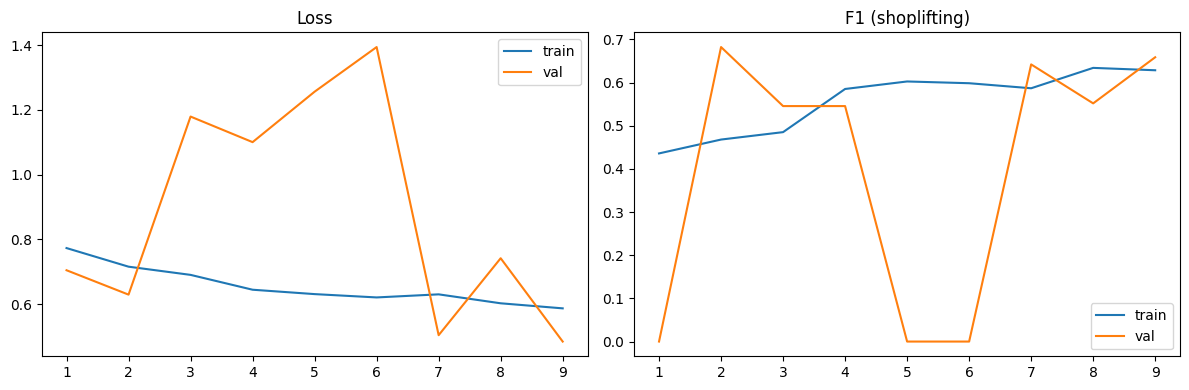

In [20]:
def compute_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f1}

counts = np.bincount(train_df.label.values, minlength=2)
class_weights = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32).to(device)
print("class weights (normal, shoplifting):", class_weights.cpu().numpy().round(2))

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train)
    total_loss, n, ys, ps = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y); n += len(y)
            ys += y.cpu().tolist(); ps += logits.argmax(1).cpu().tolist()
    return total_loss / n, compute_metrics(ys, ps)

best_path = f"{WORK}/best_{MODEL_NAME}.pt"
history, best_f1, bad_epochs = [], -1.0, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_m = run_epoch(train_loader, True)
    va_loss, va_m = run_epoch(val_loader, False)
    scheduler.step()
    history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                    "train_f1": tr_m["f1"], "val_f1": va_m["f1"], "val_acc": va_m["acc"]})
    flag = ""
    if va_m["f1"] > best_f1:
        best_f1, bad_epochs = va_m["f1"], 0
        torch.save(model.state_dict(), best_path); flag = "  <- best"
    else:
        bad_epochs += 1
    print(f"epoch {epoch:02d} | train loss {tr_loss:.4f} f1 {tr_m['f1']:.3f} | "
          f"val loss {va_loss:.4f} acc {va_m['acc']:.3f} f1 {va_m['f1']:.3f} | {time.time()-t0:.0f}s{flag}")
    if bad_epochs >= PATIENCE:
        print(f"early stopping (no val F1 improvement for {PATIENCE} epochs)")
        break

hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist.train_loss, label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.epoch, hist.train_f1, label="train"); ax[1].plot(hist.epoch, hist.val_f1, label="val"); ax[1].set_title("F1 (shoplifting)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 11. Final evaluation on the test set
The test clips were never used for training or for choosing the best epoch, so this is the honest score. **Shoplifting is the positive class (1):**
- **Precision:** of the clips we flagged as shoplifting, how many really were?
- **Recall:** of all real shoplifting clips, how many did we catch?
- **F1:** one number balancing precision and recall.

TEST  accuracy 0.6434 | precision 0.5195 | recall 0.8163 | F1 0.6349

              precision    recall  f1-score   support

      normal       0.83      0.54      0.65        80
 shoplifting       0.52      0.82      0.63        49

    accuracy                           0.64       129
   macro avg       0.67      0.68      0.64       129
weighted avg       0.71      0.64      0.65       129



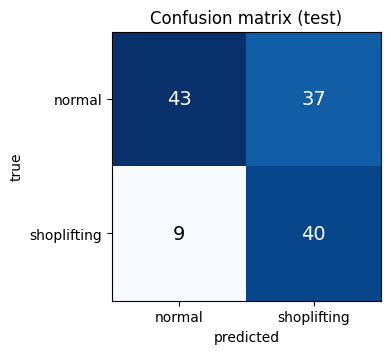

In [21]:
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()
ys, ps = [], []
with torch.no_grad():
    for x, y in test_loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x.to(device))
        ys += y.tolist(); ps += logits.argmax(1).cpu().tolist()

m = compute_metrics(ys, ps)
print(f"TEST  accuracy {m['acc']:.4f} | precision {m['precision']:.4f} | recall {m['recall']:.4f} | F1 {m['f1']:.4f}\n")
print(classification_report(ys, ps, target_names=["normal", "shoplifting"], zero_division=0))

cm = confusion_matrix(ys, ps, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "shoplifting"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "shoplifting"])
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.tight_layout(); plt.show()

## Notes
- **Missing a thief (low recall)** is usually worse than a false alarm in this application, so watch recall as well as F1.
- If the model overfits (train F1 high, val F1 low): try `MODEL_NAME = "r3d18"`, a larger `T`, or stronger augmentation.
- If several clips were cut from the same original long video, make sure all clips of one source video stay in the same split, otherwise the test score will look better than it really is.